# FEniCSx Practical Exercises · Part I
## Setup, weak forms and Examples 1–6

[Chapter guide](../README.md) · [Setup](../NOTEBOOK_README.md) · [Exercise guide](README.md)

Use DOLFINx **0.10.x**, real float64 PETSc, and a serial Python kernel. Every
baseline here uses actual finite element assembly in FEniCSx; SciPy solves the small
assembled generalized eigenproblem. No earlier notebook is required.

The runnable baselines are starting points. Complete each requested sweep, derive the
weak form, and record your evidence. Do not run the slide scripts unchanged merely
to complete a task: they can be larger and overwrite existing slide outputs.
Suggested duration: two or three 90-minute sessions.


In [1]:
import platform
import numpy as np
import scipy
from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.linalg import eigh
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=4, suppress=True)
SEED = 7
rng = np.random.default_rng(SEED)
palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449"}
plt.rcParams.update({"figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.labelcolor": palette["ink"], "text.color": palette["ink"],
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
    "axes.titleweight": "bold", "grid.alpha": .35, "lines.linewidth": 2.2,
    "figure.dpi": 100, "legend.frameon": False,
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                      ["teal", "orange", "navy", "pink", "blue"]])})
print(f"Python {platform.python_version()} · NumPy {np.__version__} · SciPy {scipy.__version__}")
print("CPU / float64 / deterministic quadrature / seed", SEED)


Python 3.14.4 · NumPy 2.4.3 · SciPy 1.17.1
CPU / float64 / deterministic quadrature / seed 7


In [2]:
import itertools
from mpi4py import MPI
from petsc4py import PETSc
import dolfinx
from dolfinx import fem, mesh, default_scalar_type
from dolfinx.fem.petsc import LinearProblem, NonlinearProblem, assemble_matrix
import basix.ufl
import ufl
assert MPI.COMM_WORLD.size == 1, "Use a normal serial Jupyter kernel; plotting/CSR conversion here is serial."
assert np.dtype(PETSc.ScalarType) == np.dtype(np.float64), "Select a real-valued float64 PETSc environment."
assert dolfinx.__version__.startswith("0.10."), "These notebooks target DOLFINx 0.10.x; use the documented environment."
print("DOLFINx",dolfinx.__version__,"· PETSc",PETSc.Sys.getVersion())
print("MPI standard",MPI.Get_version(),"·",MPI.Get_library_version().splitlines()[0])
_prefixes=itertools.count()
def prefix(label): return f"notebook_{label}_{next(_prefixes)}_"
def integral(domain, expression):
    form=fem.form(expression*ufl.dx(domain=domain,metadata={"quadrature_degree":8}))
    return float(np.real(domain.comm.allreduce(fem.assemble_scalar(form),op=MPI.SUM)))
def boundary_dofs(V):
    domain=V.mesh; tdim=domain.topology.dim
    domain.topology.create_connectivity(tdim-1,tdim)
    facets=mesh.exterior_facet_indices(domain.topology)
    return fem.locate_dofs_topological(V,tdim-1,facets)
def zero_bc(V): return fem.dirichletbc(default_scalar_type(0.),boundary_dofs(V),V)
def linear_solve(a,L,bcs=(),label="linear"):
    options={"ksp_type":"preonly","pc_type":"lu","ksp_error_if_not_converged":True}
    if label=="stokes":
        # The indefinite saddle-point system needs a pivoting sparse factorization.
        assert PETSc.Sys.hasExternalPackage("mumps"), "The Stokes exercise needs PETSc with MUMPS (included in the documented conda build)."
        options["pc_factor_mat_solver_type"]="mumps"
    problem=LinearProblem(a,L,bcs=list(bcs),petsc_options_prefix=prefix(label),petsc_options=options)
    solution=problem.solve();solution.x.scatter_forward()
    assert problem.solver.getConvergedReason()>0
    return solution


DOLFINx 0.10.0 · PETSc (3, 25, 0)
MPI standard (5, 0) · MPICH Version:      5.0.0


## 0 · Installation and the math-to-code dictionary

**Task.** Record the Python, DOLFINx, MPI, and PETSc versions printed by this kernel.
Create an interval mesh with 12 cells and P1/P2 spaces. Predict each number of degrees
of freedom before checking it. Map $u$, $v$, $\nabla u$, $dx$, essential boundary
conditions, and natural boundary conditions to their UFL/DOLFINx counterparts.

**Check.** For a serial interval with $N$ cells, P1 has $N+1$ global DOFs.
**Deliverable.** A short setup record and a weak-form-to-code table.


In [3]:
# EDIT: repeat for P2 and add a bilinear form of your choice.
setup_mesh=mesh.create_unit_interval(MPI.COMM_WORLD,12)
setup_space=fem.functionspace(setup_mesh,("Lagrange",1))
print("P1 DOFs:",setup_space.dofmap.index_map.size_global)
assert setup_space.dofmap.index_map.size_global==13


P1 DOFs: 13


## 1 · Poisson with a known solution

**Task.** Measure P1 and P2 $L^2$ and $H^1$ rates on three or more meshes, then
replace the sine by a manufactured solution with nonzero boundary values.
Derive its source and impose its boundary interpolation explicitly.

**Hint.** Integrate the error against an analytical UFL expression, not against
its interpolation into the trial space. A successful linear solve is only one check.
**Deliverable.** Rates, boundary defect, and one plot of the numerical solution.


In [4]:
def poisson_square(n=12,degree=1):
    domain=mesh.create_unit_square(MPI.COMM_WORLD,n,n)
    V=fem.functionspace(domain,("Lagrange",degree))
    x=ufl.SpatialCoordinate(domain)
    exact=ufl.sin(np.pi*x[0])*ufl.sin(np.pi*x[1])
    u,v=ufl.TrialFunction(V),ufl.TestFunction(V)
    uh=linear_solve(ufl.inner(ufl.grad(u),ufl.grad(v))*ufl.dx,
                    2*np.pi**2*exact*v*ufl.dx,[zero_bc(V)],"poisson")
    error=uh-exact
    errors=np.sqrt([integral(domain,error**2),integral(domain,ufl.inner(ufl.grad(error),ufl.grad(error)))])
    assert np.max(np.abs(uh.x.array[boundary_dofs(V)]))<1e-12
    return domain,V,uh,errors


In [5]:
# EDIT: add a mesh/degree sweep and the nonzero-boundary manufactured problem.
domain,V,uh,poisson_errors=poisson_square(n=8,degree=1)
print("Baseline integrated L2 / H1 seminorm errors:",poisson_errors)
assert np.all(poisson_errors>0)


Baseline integrated L2 / H1 seminorm errors: [0.0211 0.4318]


## 2 · Screened Neumann problem and local refinement

The starter solves $-\Delta u+u=f$ with zero normal flux and exact
$u=\cos(2\pi x)\cos(2\pi y)$. The reaction term removes the constant nullspace.

**Task.** Refine near the lower-left corner, solve on the new mesh, and compare
with uniform refinement at similar DOFs. Change the manufactured solution to have
a localized feature and justify a solution-driven marking rule.
Then derive the compatibility condition and choose a gauge for the problem obtained
by removing the reaction term. Do not apply the unconstrained LU solver to that singular system.

**Check.** The cosine has zero normal derivative on every side. A refinement aimed
at the wrong location need not improve accuracy per DOF.


In [6]:
def screened_neumann(domain):
    V=fem.functionspace(domain,("Lagrange",1))
    x=ufl.SpatialCoordinate(domain)
    exact=ufl.cos(2*np.pi*x[0])*ufl.cos(2*np.pi*x[1])
    u,v=ufl.TrialFunction(V),ufl.TestFunction(V)
    a=(ufl.inner(ufl.grad(u),ufl.grad(v))+u*v)*ufl.dx
    L=(8*np.pi**2+1)*exact*v*ufl.dx
    uh=linear_solve(a,L,label="screened_neumann")
    return V,uh,np.sqrt(integral(domain,(uh-exact)**2))


In [7]:
# EDIT: replace geometric marking by an error indicator and compare DOF budgets.
coarse=mesh.create_unit_square(MPI.COMM_WORLD,6,6)
coarse.topology.create_entities(1)
cells=np.arange(coarse.topology.index_map(2).size_local,dtype=np.int32)
mid=mesh.compute_midpoints(coarse,2,cells)
marked=cells[(mid[:,0]<.4)&(mid[:,1]<.4)]
edges=mesh.compute_incident_entities(coarse.topology,marked,2,1)
fine=mesh.refine(coarse,edges)[0]
for label,domain in [("coarse",coarse),("locally refined",fine)]:
    V,uh,error=screened_neumann(domain)
    print(label,"DOFs:",V.dofmap.index_map.size_global,"L2 error:",error)


coarse DOFs: 49 L2 error: 0.13096129156288042


locally refined DOFs: 74 L2 error: 0.11421676383612052


## 3 · The L-shaped Laplacian eigenfunction

The mesh below removes the upper-right quarter of the unit square and imposes zero
Dirichlet data on **all** boundary edges, including the reentrant corner's sides.
The generalized problem is $Kz=\lambda Mz$; boundary DOFs are removed from both matrices.

**Task.** Repeat with $N=8,16,32$, estimate the first three eigenvalues, and plot
the first eigenfunction by extending the helper to return its coefficients. Compare
refinement near the reentrant corner with uniform refinement.

**Check.** Confirm $z_i^TMz_j=\delta_{ij}$ and compute $Kz-\lambda Mz$.
Explain why eigenvalues on nested conforming spaces approach from above, and why
these eigenfunctions need not have the square's smoothness.


In [8]:
def lshape_eigenvalues(n=8,number=3):
    assert n % 2 == 0
    parent=mesh.create_unit_square(MPI.COMM_WORLD,n,n)
    cells=np.arange(parent.topology.index_map(2).size_local,dtype=np.int32)
    mid=mesh.compute_midpoints(parent,2,cells)
    retained=cells[(mid[:,0]<.5)|(mid[:,1]<.5)]
    domain=mesh.create_submesh(parent,2,retained)[0]
    V=fem.functionspace(domain,("Lagrange",1))
    u,v=ufl.TrialFunction(V),ufl.TestFunction(V)
    def csr(expression):
        A=assemble_matrix(fem.form(expression));A.assemble()
        indptr,indices,data=A.getValuesCSR()
        result=sparse.csr_matrix((data.copy(),indices.copy(),indptr.copy()),shape=A.getSize())
        A.destroy()
        return result
    K=csr(ufl.inner(ufl.grad(u),ufl.grad(v))*ufl.dx)
    M=csr(u*v*ufl.dx)
    free=np.setdiff1d(np.arange(V.dofmap.index_map.size_local),boundary_dofs(V))
    Ki,Mi=K[free,:][:,free].toarray(),M[free,:][:,free].toarray()
    eigenvalues,eigenvectors=eigh(Ki,Mi,subset_by_index=(0,number-1))
    residual=np.linalg.norm(Ki @ eigenvectors-Mi @ (eigenvectors*eigenvalues),axis=0)
    assert np.max(residual)<1e-8
    return eigenvalues,len(free)


In [9]:
# EDIT: collect the spectrum under refinement and extend the helper to return modes.
eigenvalues,dofs=lshape_eigenvalues(n=8)
print("Free DOFs:",dofs,"first eigenvalues:",eigenvalues)
assert np.all(eigenvalues>0) and np.all(np.diff(eigenvalues)>0)


Free DOFs: 33 first eigenvalues: [43.0976 66.4884 91.281 ]


## 4 · Heat equation

**Task.** Compare backward Euler and Crank–Nicolson with $\Delta t$, $\Delta t/2$,
and $\Delta t/4$. Refine space separately. Plot the discrete energy and the final
error against the analytical solution. Add a second sine mode and explain which
mode decays fastest.

**Check.** Energy must decrease for this unforced homogeneous Dirichlet problem.
**Deliverable.** Distinct temporal and spatial refinement tables.


In [10]:
def heat_interval(n=40,dt=.002,final_time=.04,theta=1.):
    domain=mesh.create_unit_interval(MPI.COMM_WORLD,n)
    V=fem.functionspace(domain,("Lagrange",1))
    old=fem.Function(V);old.interpolate(lambda x:np.sin(np.pi*x[0]))
    old.x.scatter_forward()
    steps=max(1,int(np.ceil(final_time/dt)));dt=final_time/steps
    u,v=ufl.TrialFunction(V),ufl.TestFunction(V)
    a=(u*v+theta*dt*ufl.inner(ufl.grad(u),ufl.grad(v)))*ufl.dx
    L=(old*v-(1-theta)*dt*ufl.inner(ufl.grad(old),ufl.grad(v)))*ufl.dx
    problem=LinearProblem(a,L,bcs=[zero_bc(V)],petsc_options_prefix=prefix("heat"),
             petsc_options={"ksp_type":"preonly","pc_type":"lu","ksp_error_if_not_converged":True})
    energies=[.5*integral(domain,old**2)]
    for _ in range(steps):
        new=problem.solve()
        old.x.array[:]=new.x.array;old.x.scatter_forward()
        energies.append(.5*integral(domain,old**2))
    x=ufl.SpatialCoordinate(domain)
    exact=np.exp(-np.pi**2*final_time)*ufl.sin(np.pi*x[0])
    error=np.sqrt(integral(domain,(old-exact)**2))
    coords=V.tabulate_dof_coordinates()[:,0];order=np.argsort(coords)
    return coords[order],old.x.array.real[order].copy(),np.linspace(0,final_time,steps+1),np.array(energies),error


Final L2 error: 0.0027040718856026985 energy ratio: 0.46048890961263017


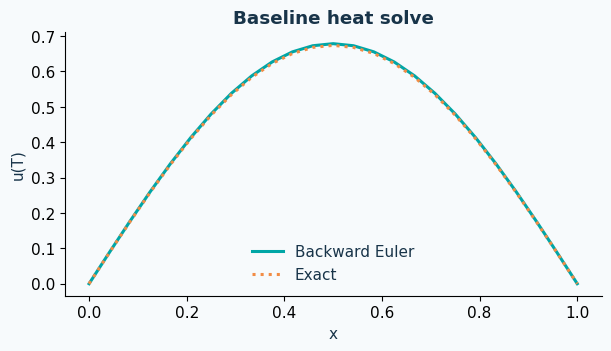

In [11]:
# EDIT: collect errors for theta=1 and theta=0.5 under independent space/time refinement.
x,u,t,E,error=heat_interval(n=24,dt=.004,theta=1.)
assert np.max(np.diff(E))<1e-11
print("Final L2 error:",error,"energy ratio:",E[-1]/E[0])
fig,ax=plt.subplots(figsize=(6,3.4),layout="constrained")
ax.plot(x,u,label="Backward Euler");ax.plot(x,np.exp(-np.pi**2*t[-1])*np.sin(np.pi*x),":",label="Exact")
ax.set(xlabel="x",ylabel="u(T)",title="Baseline heat solve");ax.legend();plt.show()


## 5 · Nonlinear Poisson

The starter solves $-[(1+\alpha u^2)u']'=f$ using an analytical manufactured
solution. DOLFINx differentiates the residual to form the Newton Jacobian.

**Task.** Sweep $\alpha=0,1,10$ and record Newton iterations and true errors.
Derive the Jacobian by hand and compare it with a directional finite difference
of the residual. Test a worse initial guess and describe the role of line search.

**Check.** Require a positive SNES convergence reason. A small update alone is
not sufficient evidence that the nonlinear residual has converged.


In [12]:
def nonlinear_poisson(strength=1.,n=32):
    domain=mesh.create_unit_interval(MPI.COMM_WORLD,n)
    V=fem.functionspace(domain,("Lagrange",1))
    x=ufl.SpatialCoordinate(domain);exact=ufl.sin(np.pi*x[0])
    u=fem.Function(V);v=ufl.TestFunction(V)
    source=-ufl.div((1+strength*exact**2)*ufl.grad(exact))
    F=((1+strength*u**2)*ufl.inner(ufl.grad(u),ufl.grad(v))-source*v)*ufl.dx
    problem=NonlinearProblem(F,u,bcs=[zero_bc(V)],petsc_options_prefix=prefix("nonlinear"),
        petsc_options={"snes_type":"newtonls","snes_rtol":1e-9,"snes_atol":1e-10,
                       "snes_max_it":30,"ksp_type":"preonly","pc_type":"lu"})
    problem.solve();u.x.scatter_forward()
    assert problem.solver.getConvergedReason()>0
    return np.sqrt(integral(domain,(u-exact)**2)),problem.solver.getIterationNumber()


In [13]:
# EDIT: sweep strength and mesh resolution, then add a Jacobian directional check.
error,iterations=nonlinear_poisson(strength=1.)
print("Nonlinear L2 error:",error,"Newton iterations:",iterations)
assert error<.02


Nonlinear L2 error: 0.000622017793140446 Newton iterations: 6


## 6 · Stokes flow in a lid-driven cavity

Use the Taylor–Hood pair P2 velocity / P1 pressure. The moving lid has a smooth
profile vanishing at its corners. One pressure DOF is fixed to select a gauge.
The weak divergence equation holds against the pressure test space; pointwise
divergence need not vanish exactly.

**Task.** Refine $N=6,12,18$ and compare the $L^2$ divergence defect, kinetic energy,
and velocity streamlines. Change the lid amplitude, predict velocity/pressure scaling,
and verify it. Explain why equal-order P1/P1 without stabilization is not an equivalent replacement.

**Hint.** Return the collapsed velocity and pressure from the helper to plot them.
**Deliverable.** Mesh study, gauge explanation, and one velocity plot.


In [14]:
def stokes_cavity(n=6,viscosity=1.):
    domain=mesh.create_unit_square(MPI.COMM_WORLD,n,n)
    velocity_element=basix.ufl.element("Lagrange",domain.basix_cell(),2,shape=(2,))
    pressure_element=basix.ufl.element("Lagrange",domain.basix_cell(),1)
    W=fem.functionspace(domain,basix.ufl.mixed_element([velocity_element,pressure_element]))
    V,_=W.sub(0).collapse();Q,_=W.sub(1).collapse()
    lid=fem.Function(V)
    # Smooth lid vanishes at its corners, avoiding discontinuous corner data.
    lid.interpolate(lambda x:np.vstack((np.where(np.isclose(x[1],1.),16*x[0]**2*(1-x[0])**2,0.),np.zeros(x.shape[1]))))
    domain.topology.create_connectivity(1,2)
    facets=mesh.exterior_facet_indices(domain.topology)
    vel_dofs=fem.locate_dofs_topological((W.sub(0),V),1,facets)
    velocity_bc=fem.dirichletbc(lid,vel_dofs,W.sub(0))
    pressure=fem.Function(Q)
    pin=fem.locate_dofs_geometrical((W.sub(1),Q),lambda x:np.isclose(x[0],0.)&np.isclose(x[1],0.))
    pressure_bc=fem.dirichletbc(pressure,pin,W.sub(1))
    u,p=ufl.TrialFunctions(W);v,q=ufl.TestFunctions(W)
    a=(viscosity*ufl.inner(ufl.grad(u),ufl.grad(v))-p*ufl.div(v)-q*ufl.div(u))*ufl.dx
    zero=fem.Constant(domain,default_scalar_type((0.,0.)))
    wh=linear_solve(a,ufl.inner(zero,v)*ufl.dx,[velocity_bc,pressure_bc],"stokes")
    velocity=wh.sub(0).collapse()
    divergence=np.sqrt(integral(domain,ufl.div(velocity)**2))
    kinetic=.5*integral(domain,ufl.inner(velocity,velocity))
    return divergence,kinetic


In [15]:
# EDIT: vary the mesh and lid profile, and return fields for visualization.
divergence,kinetic=stokes_cavity(n=6)
print("L2 divergence defect:",divergence,"kinetic energy:",kinetic)
assert np.isfinite(divergence) and kinetic>0


L2 divergence defect: 0.1138679261032348 kinetic energy: 0.018773306381628767


## Submission check

For each example, include the weak form, one modified experiment, a quantitative
verification check, and a short reflection on its limits. State mesh sizes and solver
tolerances. The printed starter diagnostics alone are not the requested report.

API references: [DOLFINx solvers](https://docs.fenicsproject.org/dolfinx/v0.10.0/python/generated/dolfinx.fem.petsc.html)
and [mesh refinement](https://docs.fenicsproject.org/dolfinx/v0.10.0/python/generated/dolfinx.mesh.html).
